My final model is as follows

- fine tuning the model by re training the weights in fourth layer and the final layer
- final layer lr=0.01
- fourth layer lr=0.0001
- using adam optimiser
- 3 epochs
- batch size 32
- pre trained model from torchgeo.models import ResNet18_Weights, resnet18, weights = ResNet18_Weights.SENTINEL2_RGB_MOCO
- my final layer needs 10 output classes
- my images are the eurostat 64x64 images converted to 224 x 224 images
- freeze all other layers
- track time for each epoch
- test model on the test set
- print confusion matrix
- plot some useful graphs regarding scalability/ model accuracy

import packages

In [1]:
import torch
import torch.nn as nn
from torchgeo.models import ResNet18_Weights, resnet18
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import time
import timm
import torch.optim as optim
import copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchgeo.models import ResNet18_Weights, resnet18

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

c:\Users\Emily\OneDrive\Pictures\Saved Pictures\Documents\GitHub\dst-sprint-2\.venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


load model

In [2]:
# Load pretrained ResNet18 model
weights = ResNet18_Weights.SENTINEL2_RGB_MOCO

model = resnet18(weights=weights)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (act1): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (drop_block): Identity()
      (act1): ReLU(inplace=True)
      (aa): Identity()
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act2): ReLU(inplace=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (b

change the final layer to fit our task

In [3]:
# Get the number of input features to the final layer
num_features = model.fc.in_features

# Replace the final fully connected layer
model.fc = nn.Linear(
    in_features=num_features,
    out_features=10
)

# Move model to GPU/CPU
model = model.to(device)

# Check the modified final layer
print(model.fc)

print("\nNumber of output classes:", model.fc.out_features)

Linear(in_features=512, out_features=10, bias=True)

Number of output classes: 10


freezing some layers

In [4]:
# Freeze all model parameters
for param in model.parameters():
    param.requires_grad = False

# Unfreeze Layer 4
for param in model.layer4.parameters():
    param.requires_grad = True

# Unfreeze final fully connected layer
for param in model.fc.parameters():
    param.requires_grad = True

# Check which layers are trainable
print("Trainable parameters:")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

# Count trainable and total parameters
trainable_params = sum(
    param.numel() for param in model.parameters()
    if param.requires_grad
)

total_params = sum(
    param.numel() for param in model.parameters()
)

print("\nTrainable parameters:", trainable_params)
print("Total parameters:", total_params)

print(
    "Percentage of trainable parameters:",
    round((trainable_params / total_params) * 100, 2),
    "%"
)

Trainable parameters:
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias

Trainable parameters: 8398858
Total parameters: 11181642
Percentage of trainable parameters: 75.11 %


optimiser

In [5]:
# Define loss function
criterion = nn.CrossEntropyLoss()

# Define Adam optimiser with separate learning rates
optimizer = optim.Adam([
    {
        'params': model.layer4.parameters(),
        'lr': 0.0001
    },
    {
        'params': model.fc.parameters(),
        'lr': 0.01
    }
])

# Check optimiser learning rates
print("Optimiser: Adam")
print("Layer 4 learning rate:", optimizer.param_groups[0]['lr'])
print("Final layer learning rate:", optimizer.param_groups[1]['lr'])

print("\nLoss function:", criterion)

Optimiser: Adam
Layer 4 learning rate: 0.0001
Final layer learning rate: 0.01

Loss function: CrossEntropyLoss()


load data

In [6]:
# Step 1: Load training images temporarily without normalisation
initial_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

initial_train_dataset = datasets.ImageFolder(
    root="../../data/train",
    transform=initial_transform
)

# Step 2: Calculate RGB mean and standard deviation
stats_loader = DataLoader(
    initial_train_dataset,
    batch_size=32,
    shuffle=False
)

channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
total_pixels = 0

for images, labels in stats_loader:
    channel_sum += images.sum(dim=[0, 2, 3])
    channel_squared_sum += (images ** 2).sum(dim=[0, 2, 3])
    total_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / total_pixels
std = torch.sqrt(channel_squared_sum / total_pixels - mean ** 2)

print("RGB mean:", mean.tolist())
print("RGB standard deviation:", std.tolist())

# Step 3: Create preprocessing transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean.tolist(),
        std=std.tolist()
    )
])

# Step 4: Load the final training and test datasets
train_dataset = datasets.ImageFolder(
    root="../../data/train",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root="../../data/test",
    transform=transform
)

# Step 5: Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Step 6: Check the datasets
print("\nClasses:", train_dataset.classes)
print("Number of classes:", len(train_dataset.classes))
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

# Check a batch of images
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

RGB mean: [0.3446079194545746, 0.38057249784469604, 0.4081569314002991]
RGB standard deviation: [0.201094850897789, 0.1351122111082077, 0.11359146237373352]

Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Number of classes: 10
Training images: 21600
Test images: 5400
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


training

In [7]:
# Number of training epochs
num_epochs = 3

# Lists to store training metrics
train_losses = []
train_accuracies = []
epoch_times = []

# Start total training timer
total_start_time = time.time()

for epoch in range(num_epochs):

    # Start epoch timer
    epoch_start_time = time.time()

    # Set model to training mode
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    # Iterate through training batches
    for images, labels in train_loader:

        # Move data to device
        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update trainable weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * images.size(0)

        # Calculate predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    # Calculate epoch metrics
    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    # Calculate epoch time
    epoch_time = time.time() - epoch_start_time

    # Store metrics
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    epoch_times.append(epoch_time)

    # Print results
    print(f"Epoch [{epoch + 1}/{num_epochs}]")
    print(f"Training Loss: {epoch_loss:.4f}")
    print(f"Training Accuracy: {epoch_accuracy:.2f}%")
    print(f"Epoch Time: {epoch_time:.2f} seconds")
    print("-" * 40)

# Calculate total training time
total_training_time = time.time() - total_start_time

print(f"Total Training Time: {total_training_time:.2f} seconds")
print(f"Average Epoch Time: {np.mean(epoch_times):.2f} seconds")

Epoch [1/3]
Training Loss: 0.2168
Training Accuracy: 93.19%
Epoch Time: 2982.70 seconds
----------------------------------------
Epoch [2/3]
Training Loss: 0.0835
Training Accuracy: 97.17%
Epoch Time: 2930.07 seconds
----------------------------------------
Epoch [3/3]
Training Loss: 0.0498
Training Accuracy: 98.31%
Epoch Time: 3009.19 seconds
----------------------------------------
Total Training Time: 8922.01 seconds
Average Epoch Time: 2973.99 seconds


evaluate on test

In [8]:
# Set model to evaluation mode
model.eval()

# Initialise evaluation variables
test_loss = 0.0
correct = 0
total = 0

# Store predictions and actual labels
all_predictions = []
all_labels = []

# Disable gradient calculations
with torch.no_grad():

    for images, labels in test_loader:

        # Move data to device
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Accumulate loss
        test_loss += loss.item() * images.size(0)

        # Get predicted classes
        _, predicted = torch.max(outputs, 1)

        # Update accuracy statistics
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        # Store predictions and actual labels
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate final test metrics
test_loss = test_loss / total
test_accuracy = 100 * correct / total

# Print results
print("Test Results")
print("-" * 40)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct Predictions: {correct}/{total}")

Test Results
----------------------------------------
Test Loss: 0.0857
Test Accuracy: 97.44%
Correct Predictions: 5262/5400


report

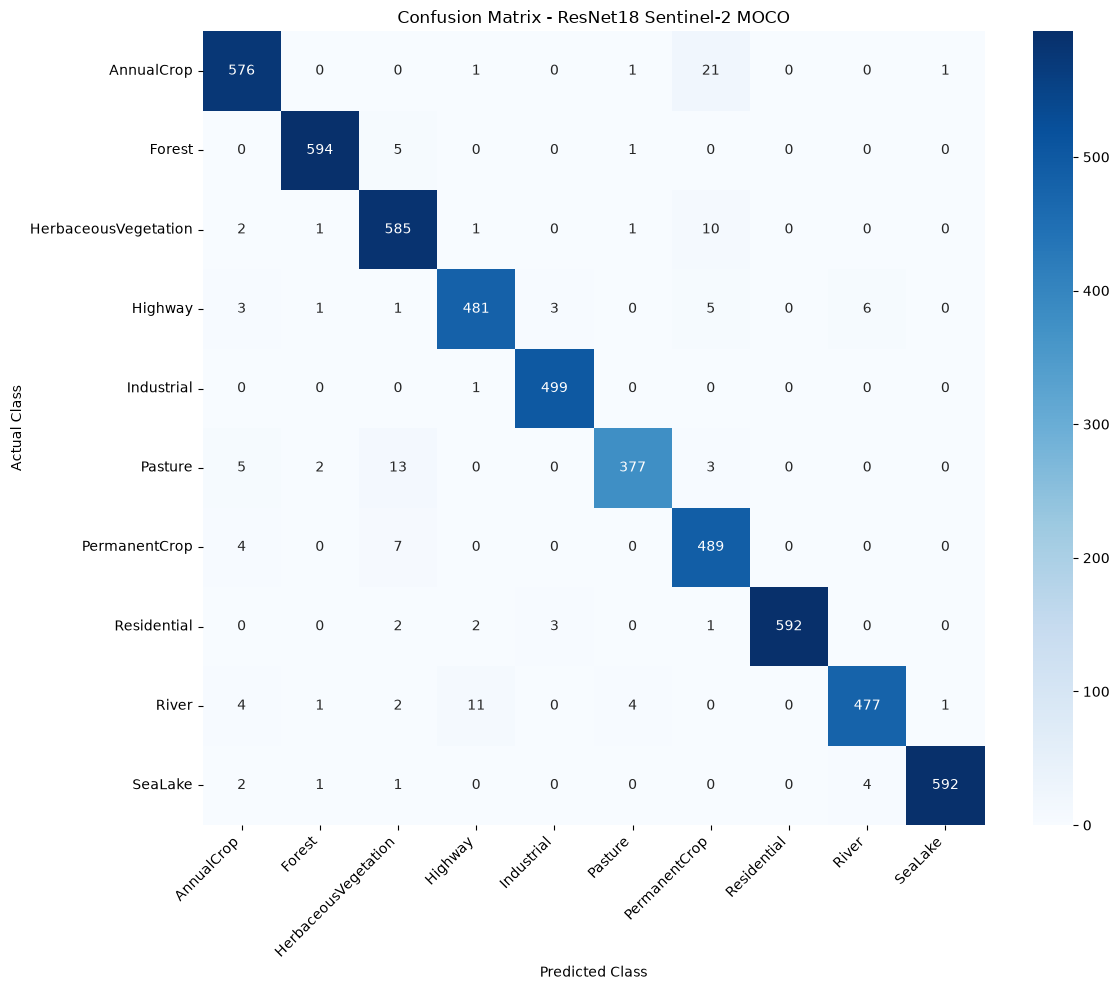


Classification Report
------------------------------------------------------------
                      precision    recall  f1-score   support

          AnnualCrop     0.9664    0.9600    0.9632       600
              Forest     0.9900    0.9900    0.9900       600
HerbaceousVegetation     0.9497    0.9750    0.9622       600
             Highway     0.9678    0.9620    0.9649       500
          Industrial     0.9881    0.9980    0.9930       500
             Pasture     0.9818    0.9425    0.9617       400
       PermanentCrop     0.9244    0.9780    0.9504       500
         Residential     1.0000    0.9867    0.9933       600
               River     0.9795    0.9540    0.9666       500
             SeaLake     0.9966    0.9867    0.9916       600

            accuracy                         0.9744      5400
           macro avg     0.9744    0.9733    0.9737      5400
        weighted avg     0.9749    0.9744    0.9745      5400



In [9]:
# Get class names from the dataset
class_names = test_dataset.classes

# Calculate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - ResNet18 Sentinel-2 MOCO")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print classification report
print("\nClassification Report")
print("-" * 60)

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
))

We'll create four graphs:
1. Training loss across epochs.
2. Training accuracy across epochs.
3. Training time per epoch.
4. Trainable versus frozen parameters

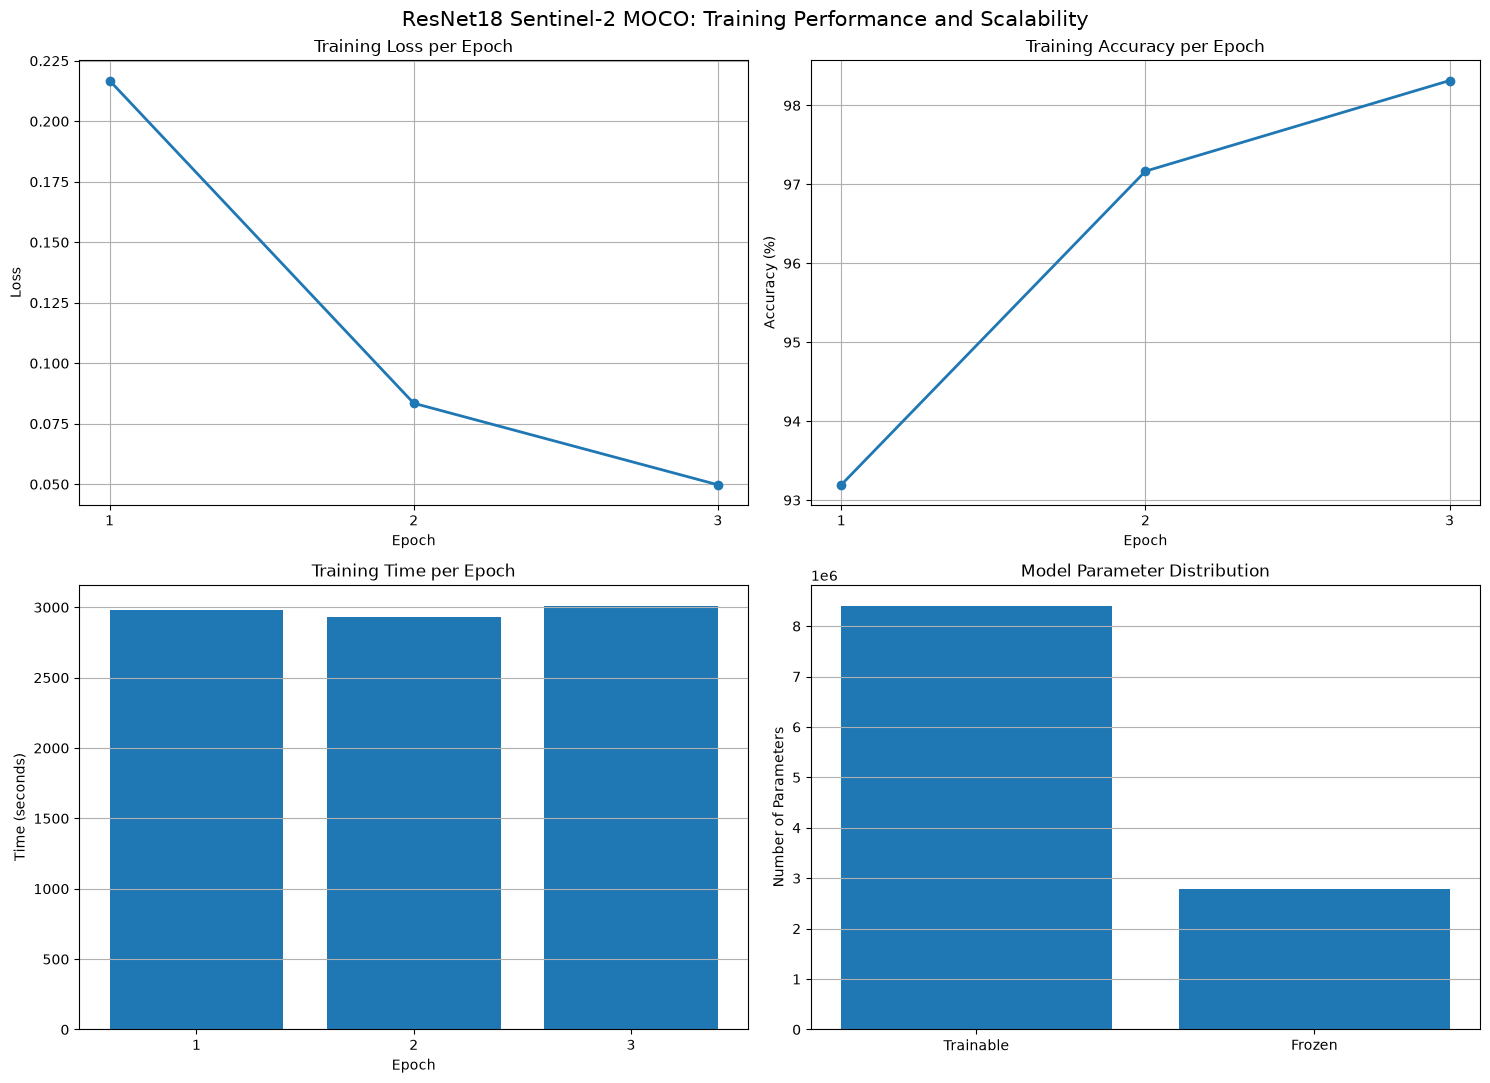

In [10]:
# Create a figure with 2x2 subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

epochs = range(1, num_epochs + 1)

# 1. Training Loss
axes[0, 0].plot(
    epochs,
    train_losses,
    marker='o',
    linewidth=2
)

axes[0, 0].set_title("Training Loss per Epoch")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].set_xticks(list(epochs))
axes[0, 0].grid(True)


# 2. Training Accuracy
axes[0, 1].plot(
    epochs,
    train_accuracies,
    marker='o',
    linewidth=2
)

axes[0, 1].set_title("Training Accuracy per Epoch")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy (%)")
axes[0, 1].set_xticks(list(epochs))
axes[0, 1].grid(True)


# 3. Training Time per Epoch
axes[1, 0].bar(
    list(epochs),
    epoch_times
)

axes[1, 0].set_title("Training Time per Epoch")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Time (seconds)")
axes[1, 0].set_xticks(list(epochs))
axes[1, 0].grid(axis='y')


# 4. Trainable vs Frozen Parameters
frozen_params = total_params - trainable_params

axes[1, 1].bar(
    ["Trainable", "Frozen"],
    [trainable_params, frozen_params]
)

axes[1, 1].set_title("Model Parameter Distribution")
axes[1, 1].set_ylabel("Number of Parameters")
axes[1, 1].grid(axis='y')


plt.suptitle(
    "ResNet18 Sentinel-2 MOCO: Training Performance and Scalability",
    fontsize=15
)

plt.tight_layout()
plt.show()

final report

In [11]:
print("=" * 55)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 55)

print("\nModel: ResNet18 Sentinel-2 RGB MOCO")
print("Architecture: Transfer Learning / Fine-tuning")
print("Image Size: 224 x 224")
print("Number of Classes:", len(class_names))

print("\nTraining Configuration")
print("-" * 55)
print("Epochs:", num_epochs)
print("Batch Size:", train_loader.batch_size)
print("Optimiser: Adam")
print("Layer 4 Learning Rate: 0.0001")
print("Final Layer Learning Rate: 0.01")
print("Loss Function: CrossEntropyLoss")

print("\nTrainable Parameters")
print("-" * 55)
print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Frozen Parameters: {frozen_params:,}")
print(f"Trainable Percentage: {100 * trainable_params / total_params:.2f}%")

print("\nTraining Performance")
print("-" * 55)
print(f"Final Training Loss: {train_losses[-1]:.4f}")
print(f"Final Training Accuracy: {train_accuracies[-1]:.2f}%")
print(f"Total Training Time: {total_training_time:.2f} seconds")
print(f"Average Epoch Time: {np.mean(epoch_times):.2f} seconds")

print("\nTesting Performance")
print("-" * 55)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

print("=" * 55)

FINAL MODEL PERFORMANCE SUMMARY

Model: ResNet18 Sentinel-2 RGB MOCO
Architecture: Transfer Learning / Fine-tuning
Image Size: 224 x 224
Number of Classes: 10

Training Configuration
-------------------------------------------------------
Epochs: 3
Batch Size: 32
Optimiser: Adam
Layer 4 Learning Rate: 0.0001
Final Layer Learning Rate: 0.01
Loss Function: CrossEntropyLoss

Trainable Parameters
-------------------------------------------------------
Total Parameters: 11,181,642
Trainable Parameters: 8,398,858
Frozen Parameters: 2,782,784
Trainable Percentage: 75.11%

Training Performance
-------------------------------------------------------
Final Training Loss: 0.0498
Final Training Accuracy: 98.31%
Total Training Time: 8922.01 seconds
Average Epoch Time: 2973.99 seconds

Testing Performance
-------------------------------------------------------
Test Loss: 0.0857
Test Accuracy: 97.44%


In [12]:
# Save final model
torch.save(
    model.state_dict(),
    "resnet18_eurostat_final.pth"
)

print("Final model saved successfully!")

Final model saved successfully!


C:\Users\Emily\AppData\Local\Temp\ipykernel_22740\60960419.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_tensor = torch.tensor(mean).view(3, 1, 1)
C:\Users\Emily\AppData\Local\Temp\ipykernel_22740\60960419.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  std_tensor = torch.tensor(std).view(3, 1, 1)


IndexError: index 10 is out of bounds for axis 0 with size 10

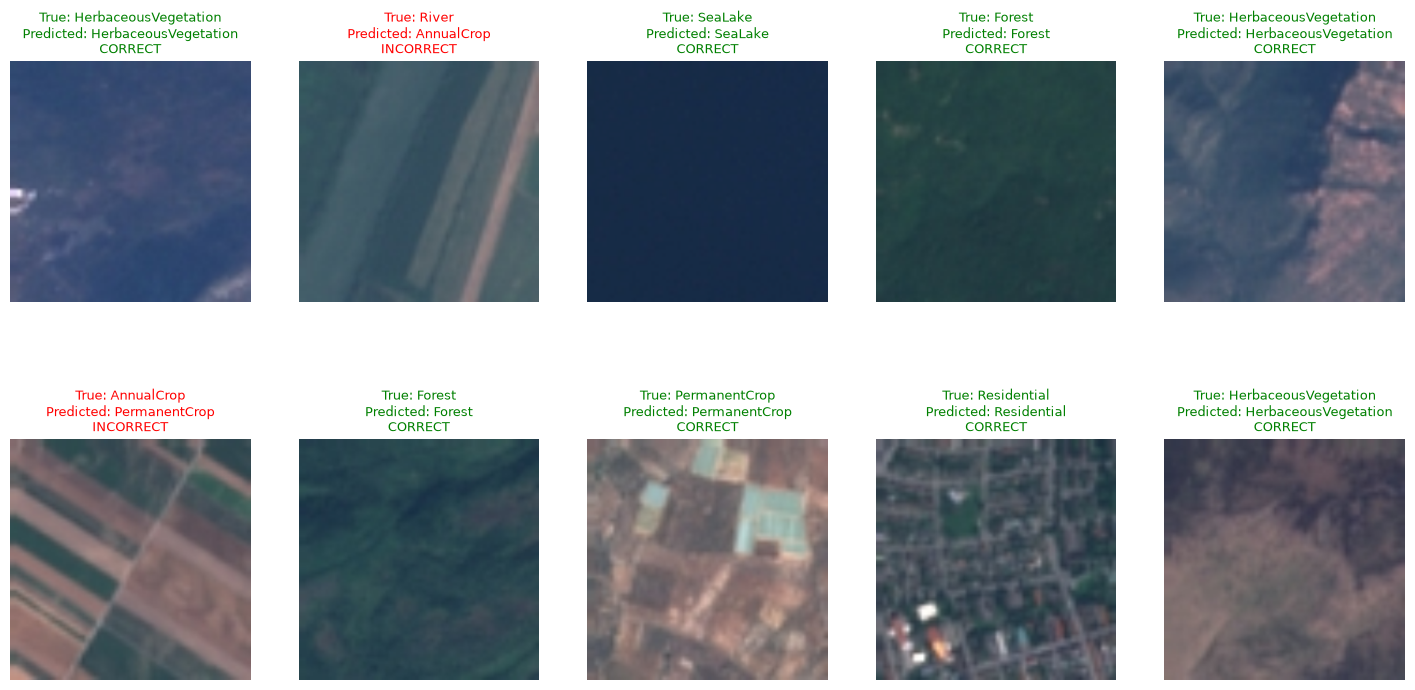

In [16]:
import random
import matplotlib.pyplot as plt
import numpy as np

# Number of examples to display
num_correct = 12
num_incorrect = 3

# Lists to store correctly and incorrectly classified images
correct_indices = []
incorrect_indices = []

# Identify correct and incorrect predictions
for idx in range(len(all_labels)):

    if all_predictions[idx] == all_labels[idx]:
        correct_indices.append(idx)
    else:
        incorrect_indices.append(idx)

# Randomly select examples
selected_correct = random.sample(
    correct_indices,
    min(num_correct, len(correct_indices))
)

selected_incorrect = random.sample(
    incorrect_indices,
    min(num_incorrect, len(incorrect_indices))
)

# Combine selected indices
selected_indices = selected_correct + selected_incorrect

# Shuffle so correct and incorrect examples are mixed
random.shuffle(selected_indices)

# Get normalisation statistics
mean_tensor = torch.tensor(mean).view(3, 1, 1)
std_tensor = torch.tensor(std).view(3, 1, 1)

# Create plot
fig, axes = plt.subplots(2, 5, figsize=(18, 9))
axes = axes.flatten()

for i, idx in enumerate(selected_indices):

    # Get image and labels
    image, true_label = test_dataset[idx]

    predicted_label = all_predictions[idx]

    # Reverse normalisation
    image = image * std_tensor + mean_tensor

    # Convert to numpy for plotting
    image = image.permute(1, 2, 0).numpy()

    # Clip values to valid RGB range
    image = np.clip(image, 0, 1)

    # Display image
    axes[i].imshow(image)

    true_name = class_names[true_label]
    predicted_name = class_names[predicted_label]

    # Determine whether prediction is correct
    if predicted_label == true_label:
        result = "CORRECT"
        colour = "green"
    else:
        result = "INCORRECT"
        colour = "red"

    axes[i].set_title(
        f"True: {true_name}\n"
        f"Predicted: {predicted_name}\n"
        f"{result}",
        color=colour,
        fontsize=9
    )

    axes[i].axis("off")

# Hide unused subplots if there are fewer than 10 examples
for j in range(len(selected_indices), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "ResNet18 Eurostat Classification: Correct vs Incorrect Predictions",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Print selection summary
print("Correct examples displayed:", len(selected_correct))
print("Incorrect examples displayed:", len(selected_incorrect))